# Tugas: Clustering Artikel Klarifikasi Hoaks Komdigi

Notebook ini menerapkan K-Means dan DBSCAN pada teks di `komdigi_hoaks.csv`. Kolom `title`, `excerpt`, dan `body_text` digabungkan lalu diubah menjadi fitur TF-IDF.

`topics` adalah label kategori topik, sedangkan `category` hanya memiliki satu nilai. Karena itu, `topics` tidak digunakan untuk membentuk cluster; label tersebut hanya dipakai untuk evaluasi eksternal dan interpretasi. Hasil cluster bukan klasifikasi benar/salah klaim.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

# Dukung eksekusi dari root repository maupun folder notebook.
data_candidates = [
    Path("../../data/komdigi_hoaks.csv"),
]
data_path = next((path for path in data_candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("File komdigi_hoaks.csv tidak ditemukan.")

df = pd.read_csv(data_path)
print(f"Lokasi dataset: {data_path.resolve()}")
print("Ukuran awal:", df.shape)
print("Jumlah nilai unik category:", df["category"].nunique())

# URL menjadi kunci deduplikasi; metadata tidak dimasukkan sebagai fitur clustering.
df = df.drop_duplicates(subset="url", keep="first").copy()
text_columns = ["title", "excerpt", "body_text"]
df[text_columns] = df[text_columns].fillna("").astype(str)
df["article_text"] = (
    df[text_columns]
    .agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
df["topics"] = df["topics"].str.strip()

vectorizer = TfidfVectorizer(
    max_features=5000,
    min_df=2,
    ngram_range=(1, 2),
    sublinear_tf=True,
)
X = vectorizer.fit_transform(df["article_text"])
print("Artikel setelah deduplikasi:", len(df))
print("Matriks TF-IDF:", X.shape)
print("Distribusi topics:")
display(df["topics"].value_counts().rename("jumlah artikel").to_frame())
display(df[["title", "topics", "article_text"]].head())

Lokasi dataset: D:\Kuliah\Kelas\Semester 5\Pembelajaran Mesin\TUGAS\PRAKTIKUM\data\komdigi_hoaks.csv
Ukuran awal: (4176, 13)
Jumlah nilai unik category: 1
Artikel setelah deduplikasi: 4162
Matriks TF-IDF: (4162, 5000)
Distribusi topics:


,jumlah artikel
topics,
Hoaks,3524
Penipuan,286
Pejabat Publik,135
Masyarakat Digital,102
Program/Kebijakan,59
Kesehatan,56


,title,topics,article_text
0,[HOAKS] Tautan Pencairan BSU September 2026 Se...,Hoaks,[HOAKS] Tautan Pencairan BSU September 2026 Se...
1,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...,Hoaks,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...
2,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...,Hoaks,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...
3,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...,Hoaks,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...
4,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...,Hoaks,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...


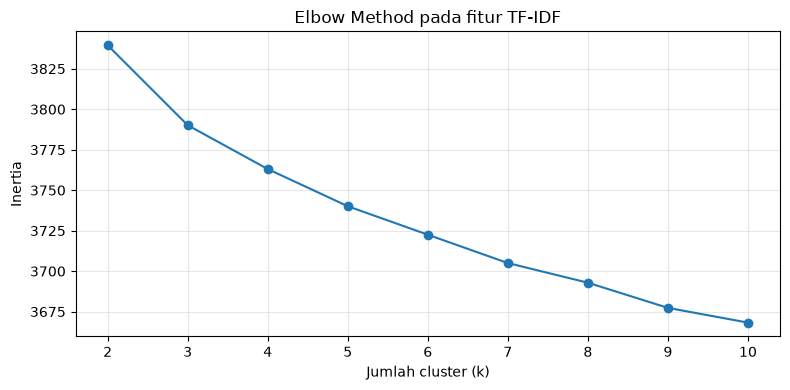

In [2]:
# K-Means: cari kandidat jumlah cluster memakai inertia (Elbow Method).
k_values = range(2, 11)
inertia = []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(X)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(list(k_values), inertia, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method pada fitur TF-IDF")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

k=2: silhouette cosine=0.0330
k=3: silhouette cosine=0.0306
k=4: silhouette cosine=0.0292
k=5: silhouette cosine=0.0257
k=6: silhouette cosine=0.0286
k=7: silhouette cosine=0.0214
k=8: silhouette cosine=0.0187
k=9: silhouette cosine=0.0250
k=10: silhouette cosine=0.0312
K terpilih berdasarkan silhouette sampel: 2


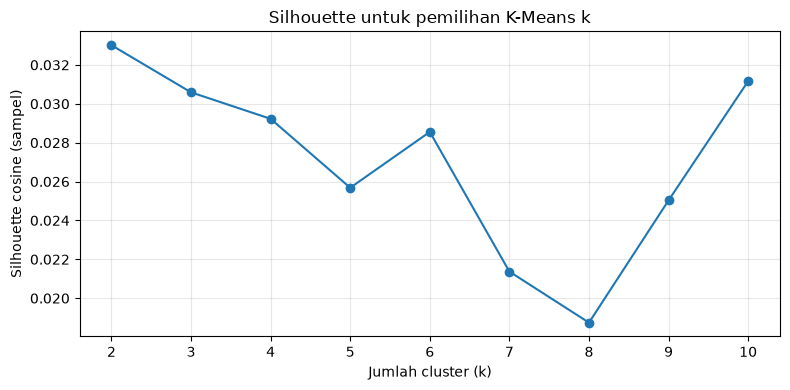

In [3]:
# Silhouette cosine dihitung pada sampel agar ukuran komputasi terkendali.
k_values = range(2, 11)
silhouette_scores = []
sample_size = min(1000, X.shape[0])
for k in k_values:
    candidate_model = KMeans(n_clusters=k, n_init=10, random_state=42)
    candidate_labels = candidate_model.fit_predict(X)
    score = silhouette_score(
        X,
        candidate_labels,
        metric="cosine",
        sample_size=sample_size,
        random_state=42,
    )
    silhouette_scores.append(score)
    print(f"k={k}: silhouette cosine={score:.4f}")

best_k = list(k_values)[int(np.argmax(silhouette_scores))]
print(f"K terpilih berdasarkan silhouette sampel: {best_k}")
plt.figure(figsize=(8, 4))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Silhouette cosine (sampel)")
plt.title("Silhouette untuk pemilihan K-Means k")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

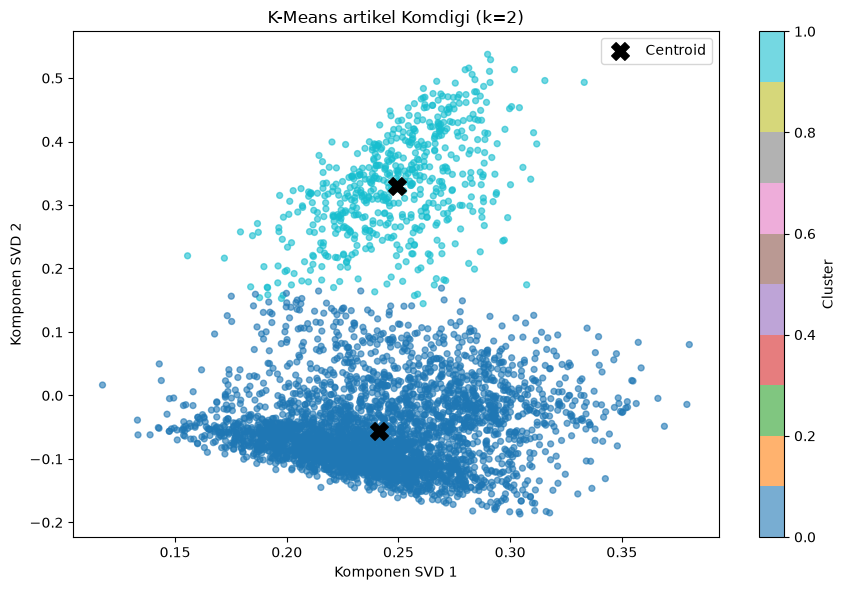

Ukuran tiap cluster:


,jumlah artikel
kmeans_cluster,
0,3589
1,573


Variansi yang dijelaskan SVD 2D: 0.0247


In [4]:
# Latih K-Means pada seluruh dokumen dengan k hasil evaluasi.
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X)
df["kmeans_cluster"] = kmeans_labels

# SVD hanya untuk visualisasi 2D; model clustering tetap memakai fitur TF-IDF.
svd_2d = TruncatedSVD(n_components=2, random_state=42)
X_2d = svd_2d.fit_transform(X)
centers_2d = svd_2d.transform(kmeans.cluster_centers_)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=kmeans_labels,
                      cmap="tab10", s=18, alpha=0.6)
plt.scatter(centers_2d[:, 0], centers_2d[:, 1], c="black", marker="X",
            s=160, label="Centroid")
plt.xlabel("Komponen SVD 1")
plt.ylabel("Komponen SVD 2")
plt.title(f"K-Means artikel Komdigi (k={best_k})")
plt.colorbar(scatter, label="Cluster")
plt.legend()
plt.tight_layout()
plt.show()
print("Ukuran tiap cluster:")
display(df["kmeans_cluster"].value_counts().sort_index().rename("jumlah artikel").to_frame())
print("Variansi yang dijelaskan SVD 2D:", round(svd_2d.explained_variance_ratio_.sum(), 4))

In [5]:
# Evaluasi eksternal K-Means dan istilah teratas per cluster.
print(f"K-Means ARI vs topics: {adjusted_rand_score(df['topics'], kmeans_labels):.4f}")
print(f"K-Means NMI vs topics: {normalized_mutual_info_score(df['topics'], kmeans_labels):.4f}")
display(pd.crosstab(df["kmeans_cluster"], df["topics"]))

feature_names = vectorizer.get_feature_names_out()
for cluster_id in range(best_k):
    cluster_rows = kmeans_labels == cluster_id
    term_weights = np.asarray(X[cluster_rows].sum(axis=0)).ravel()
    top_indices = np.argsort(term_weights)[-10:][::-1]
    print(f"Cluster {cluster_id} ({cluster_rows.sum()} artikel): "
          f"{', '.join(feature_names[top_indices])}")

K-Means ARI vs topics: 0.1211
K-Means NMI vs topics: 0.1211


topics,Hoaks,Kesehatan,Masyarakat Digital,Pejabat Publik,Penipuan,Program/Kebijakan
kmeans_cluster,,,,,,
0,3112,56,70,12,280,59
1,412,0,32,123,6,0


Cluster 0 (3589 artikel): yang, di, video, tidak, tersebut, hoaks, dan, com, id, dari
Cluster 1 (573 artikel): whatsapp, akun whatsapp, akun, mengatasnamakan, whatsapp mengatasnamakan, yang mengatasnamakan, hoaks akun, nomor, kabupaten, akun tersebut


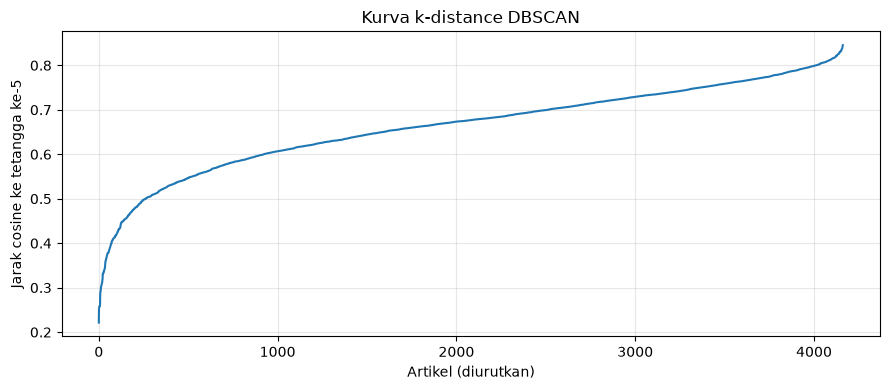

,distance
0.10,0.533142
0.25,0.609635
0.50,0.676754
0.75,0.735168
0.90,0.774114


In [6]:
# DBSCAN: gunakan kurva k-distance untuk memilih rentang eps.
min_samples = 5
neighbors = NearestNeighbors(n_neighbors=min_samples, metric="cosine", n_jobs=-1)
neighbors.fit(X)
distances, _ = neighbors.kneighbors(X)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 4))
plt.plot(np.arange(len(k_distances)), k_distances)
plt.xlabel("Artikel (diurutkan)")
plt.ylabel(f"Jarak cosine ke tetangga ke-{min_samples}")
plt.title("Kurva k-distance DBSCAN")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
display(pd.Series(k_distances).quantile([0.1, 0.25, 0.5, 0.75, 0.9])
        .rename("distance").to_frame())

DBSCAN eps=0.7, min_samples=5
Jumlah cluster (tanpa noise): 19
Jumlah noise: 967 (23.2%)


,jumlah artikel
dbscan_cluster,
-1,967
0,3075
1,11
2,8
3,5
4,4
5,6
6,21
7,5


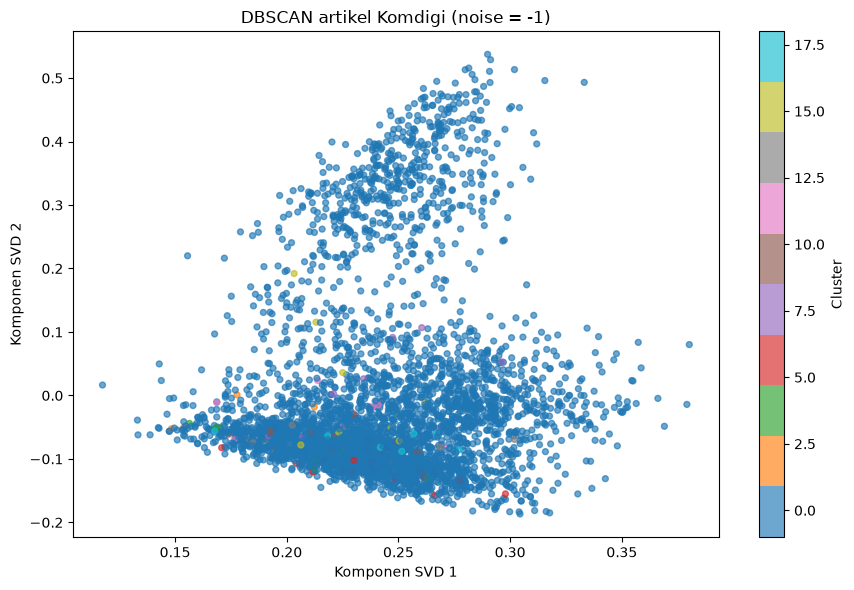

In [7]:
# Jalankan DBSCAN pada representasi TF-IDF menggunakan cosine distance.
eps = 0.7
dbscan = DBSCAN(eps=eps, min_samples=min_samples, metric="cosine", n_jobs=-1)
dbscan_labels = dbscan.fit_predict(X)
df["dbscan_cluster"] = dbscan_labels
n_clusters = len(set(dbscan_labels) - {-1})
noise_mask = dbscan_labels == -1
noise_count = int(noise_mask.sum())
print(f"DBSCAN eps={eps}, min_samples={min_samples}")
print("Jumlah cluster (tanpa noise):", n_clusters)
print(f"Jumlah noise: {noise_count} ({noise_count / len(df):.1%})")
display(df["dbscan_cluster"].value_counts().sort_index().rename("jumlah artikel").to_frame())

plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=dbscan_labels,
                      cmap="tab10", s=18, alpha=0.65)
plt.xlabel("Komponen SVD 1")
plt.ylabel("Komponen SVD 2")
plt.title("DBSCAN artikel Komdigi (noise = -1)")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

In [8]:
# Evaluasi eksternal DBSCAN terhadap topics; topics tidak digunakan saat clustering.
print(f"DBSCAN ARI vs topics: {adjusted_rand_score(df['topics'], dbscan_labels):.4f}")
print(f"DBSCAN NMI vs topics: {normalized_mutual_info_score(df['topics'], dbscan_labels):.4f}")
display(pd.crosstab(df["dbscan_cluster"], df["topics"]))

non_noise = ~noise_mask
non_noise_labels = dbscan_labels[non_noise]
if len(np.unique(non_noise_labels)) >= 2:
    silhouette_sample_size = min(1000, int(non_noise.sum()))
    score = silhouette_score(
        X[non_noise],
        non_noise_labels,
        metric="cosine",
        sample_size=silhouette_sample_size,
        random_state=42,
    )
    print(f"Silhouette cosine non-noise (sampel): {score:.4f}")
else:
    print("Silhouette tidak dihitung: diperlukan minimal dua cluster non-noise.")

DBSCAN ARI vs topics: -0.0594
DBSCAN NMI vs topics: 0.0341


topics,Hoaks,Kesehatan,Masyarakat Digital,Pejabat Publik,Penipuan,Program/Kebijakan
dbscan_cluster,,,,,,
-1,878,25,22,3,19,20
0,2533,29,78,132,266,37
1,11,0,0,0,0,0
2,8,0,0,0,0,0
3,5,0,0,0,0,0
4,4,0,0,0,0,0
5,6,0,0,0,0,0
6,21,0,0,0,0,0
7,5,0,0,0,0,0


Silhouette cosine non-noise (sampel): -0.0286


In [9]:
# Eksperimen parameter DBSCAN: jumlah cluster dan persentase noise.
eps_values = [0.55, 0.6, 0.65, 0.7, 0.75]
min_samples_values = [3, 5, 10]
results = []
for eps_value in eps_values:
    for min_samples_value in min_samples_values:
        candidate_labels = DBSCAN(
            eps=eps_value,
            min_samples=min_samples_value,
            metric="cosine",
            n_jobs=-1,
        ).fit_predict(X)
        cluster_sizes = pd.Series(candidate_labels)[candidate_labels != -1].value_counts()
        results.append({
            "eps": eps_value,
            "min_samples": min_samples_value,
            "clusters": len(set(candidate_labels) - {-1}),
            "noise": int(np.sum(candidate_labels == -1)),
            "noise_persen": round(np.mean(candidate_labels == -1) * 100, 2),
            "cluster_terbesar": int(cluster_sizes.max()) if not cluster_sizes.empty else 0,
            "ARI_vs_topics": adjusted_rand_score(df["topics"], candidate_labels),
        })

results_df = pd.DataFrame(results)
display(results_df.round(3))

,eps,min_samples,clusters,noise,noise_persen,cluster_terbesar,ARI_vs_topics
0,0.55,3,115,2930,70.40,348,0.079
1,0.55,5,49,3296,79.19,313,0.081
2,0.55,10,12,3680,88.42,260,0.101
3,0.60,3,123,2271,54.57,935,0.038
4,0.60,5,62,2644,63.53,442,0.078
5,0.60,10,17,3298,79.24,375,0.101
6,0.65,3,81,1500,36.04,2035,-0.024
7,0.65,5,49,1835,44.09,1819,-0.002
8,0.65,10,24,2505,60.19,1258,0.054
9,0.70,3,30,744,17.88,3281,-0.065
